# Simple baseline model of FER 2013

This notebook has a basic example of a pipeline to train and evaluate a model on FER 2-13. This model is far from perfect, so you have some room to improve in here

**Environment:** `environments/environment-general.yml` (Python 3.12). Create it with `conda env create -f environments/environment-general.yml`.


In [1]:
#All imports for this notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#set up and validate data directory
# Find the repository root from wherever Jupyter starts (the notebook's own folder).
ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "auxFiles/kdef_subject_split.pkl").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found")
DATA = ROOT / "data" / "fer"

print(DATA)
print(DATA.exists())   # should print True

/Users/henriquedasilvacouto/workspace/TUe-Master_AI_and_ES/Masters-database/5ARE0_2026-GS1/Assignment_2/ml-emotionalrecognition/data/fer
True


## Dataset
### Part 1 of the dataset: Loading the data and splitting it in training, validation and test sets
They will finetune their models in the training and validation sets. We want the reported confusion matrix and other performance measurements on the validation and test sets.

The version of FER 2013 in Kaggle stores all the images and labels for the three splits in a single .csv file. The very first steo is to split this into the three sets so that we avoid data leakages

In [2]:
# Load the dataset
df = pd.read_csv(DATA / "fer2013.csv")

# The dataset already contains the splits, specified in the "Usage" field
print(df['Usage'].value_counts())

# Training -> train, PublicTest -> validation, PrivateTest -> test
train_df      = df[df['Usage'] == 'Training'].copy()
validation_df = df[df['Usage'] == 'PublicTest'].copy()
test_df       = df[df['Usage'] == 'PrivateTest'].copy()

train_df.to_csv(DATA / "fer2013_train.csv", encoding="utf-8", index=False)
validation_df.to_csv(DATA/ "fer2013_validation.csv", encoding="utf-8", index=False)
test_df.to_csv(DATA / "fer2013_test.csv", encoding="utf-8", index=False)

print(len(train_df), len(validation_df), len(test_df))

Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64
28709 3589 3589


### Part 2 of the dataset: Basic statistics on class and displaying samples for each class

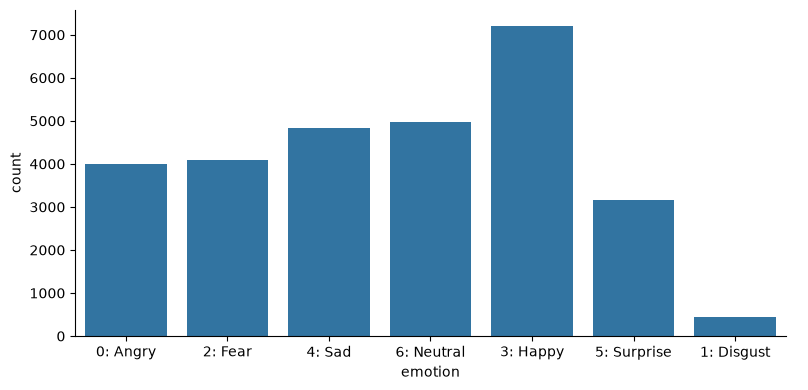

In [3]:
emotionDict = {
    0:'0: Angry',
    1:'1: Disgust',
    2:'2: Fear',
    3:'3: Happy',
    4:'4: Sad',
    5:'5: Surprise',
    6:'6: Neutral'
}


sns.catplot(data=train_df.replace({'emotion': emotionDict}), kind='count', x='emotion', height=4, aspect=2)

#sns.countplot(x ='emotion', data = trai_df)
plt.show()

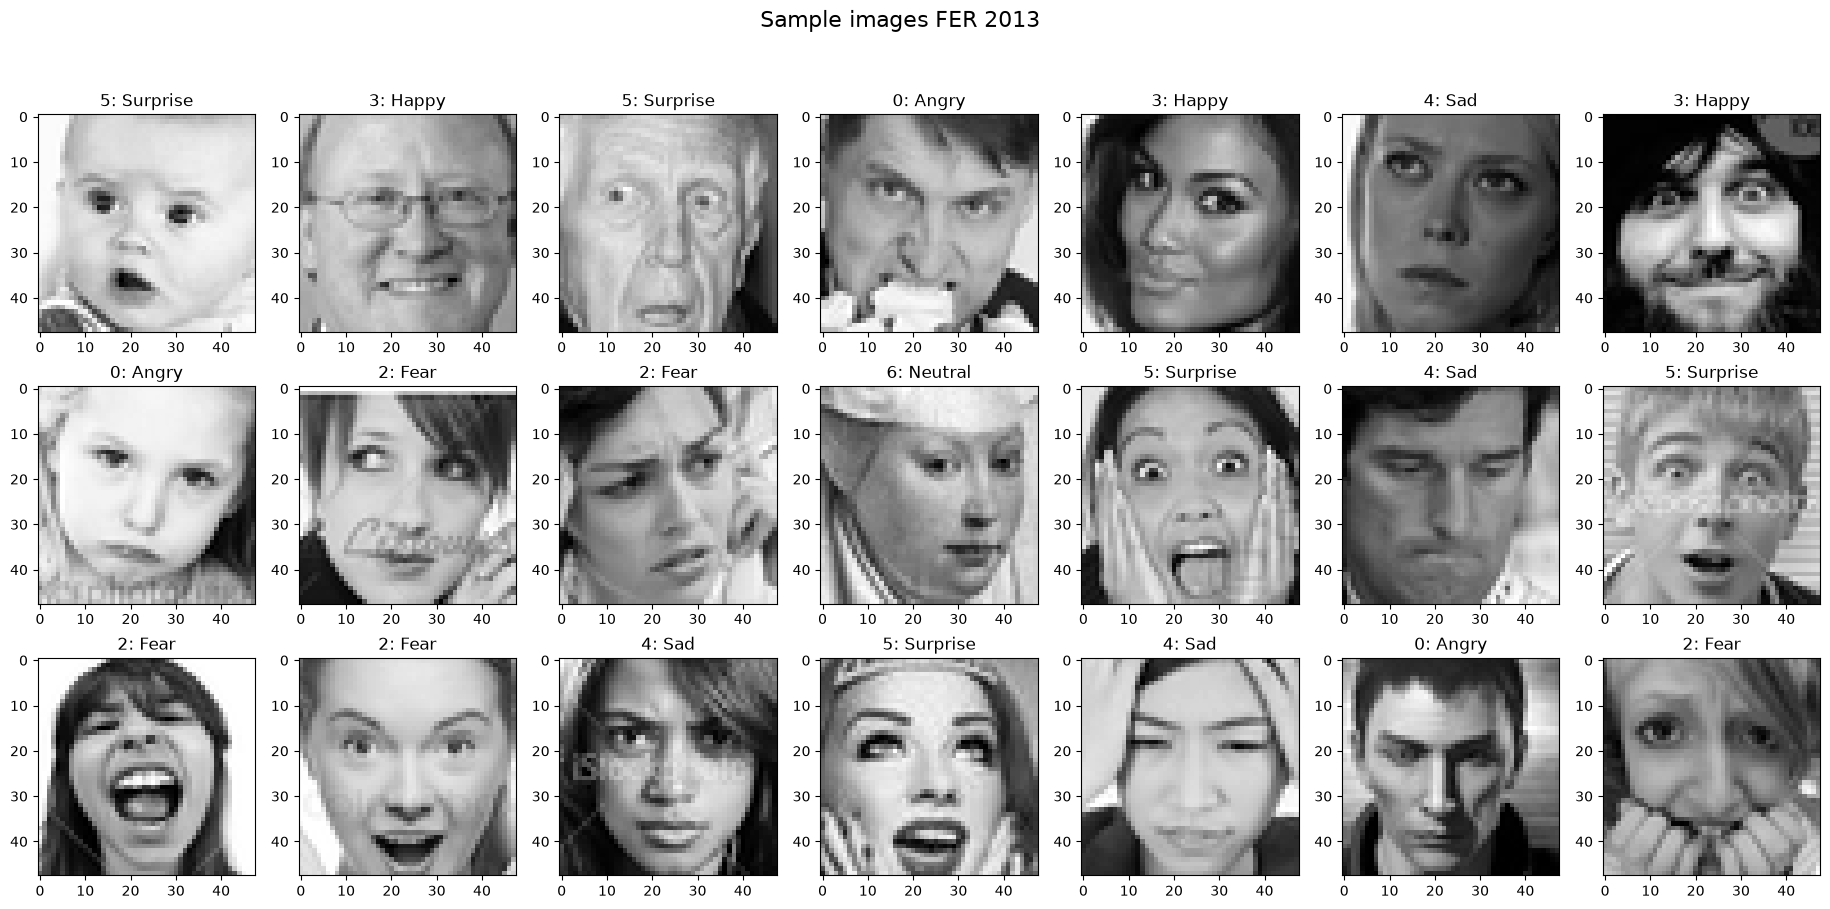

In [4]:
# Now making some plots
random_rows = df.sample(n=21, random_state=43)
imgs = [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in random_rows['pixels']]
lbl =  random_rows['emotion'].values

fig, axes = plt.subplots(nrows=3, ncols=7, figsize=(23, 10))
fig.suptitle('Sample images FER 2013', fontsize=16)

# Loop through each subplot and customize
for i in range(7):
    for j in range(3):
        ax = axes[j, i]
        ax.imshow(imgs[j*7+i], cmap="gray") 
        ax.set_title('%s'%(emotionDict[lbl[j*7+i]]))
        #ax.grid(True)
plt.show()
